# TimeSformer Crime Detection Model - Violence/Theft/Normal Classification
## TimeSformer-T Transformer with Full Training Pipeline and Performance Visualization\n

## 1. Import Required Libraries\n

In [12]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import gc
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")


PyTorch version: 2.9.0+cu126
Torchvision version: 0.24.0+cu126
CUDA available: True


## 2. Define Dataset Paths and Classes\n

In [13]:
RWF       = "/kaggle/input/datasets/daniazehra/rwf-2000/RWF-2000"
UCF_CRIME = "/kaggle/input/datasets/alirakhmaev/ucf-crime-full"
CAMNUVEOM = "/kaggle/input/datasets/elattarmohamed/camnuveom/camnuveom/videos/samples/training"

MAIN_CLASSES = ['violence', 'theft', 'normal']

UCF_TO_MAIN_CLASS = {
    'Shoplifting': 'theft',
    'Stealing':    'theft',
    'Robbery':     'theft',
    'Burglary':    'theft',
    'Normal':      'normal',
}

NUM_FRAMES = 8
IMG_SIZE   = 224

print(f"Main Classes: {MAIN_CLASSES}")
print(f"Number of Classes: {len(MAIN_CLASSES)}")


Main Classes: ['violence', 'theft', 'normal']
Number of Classes: 3


## 3. Data Loading Functions\n

In [14]:
def load_camnuveom():
    rows = []
    for cls in ["anomaly", "normal"]:
        class_dir = os.path.join(CAMNUVEOM, cls)
        if not os.path.exists(class_dir): continue
        main_label = "theft" if cls == "anomaly" else "normal"
        for video_path in glob.glob(os.path.join(class_dir, "*.mp4")):
            rows.append({'clip_path': video_path, 'main_label': main_label,
                         'sub_label': main_label, 'dataset': 'camnuveon',
                         'original_class': cls, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from CAMNUVEON")
    return df

def load_rwf():
    rows = []
    for split in ["train", "val"]:
        for cls in ["Fight", "NonFight"]:
            class_dir = os.path.join(RWF, split, cls)
            if not os.path.exists(class_dir): continue
            main_label = "violence" if cls == "Fight" else "normal"
            for video_path in glob.glob(os.path.join(class_dir, "*.avi")):
                rows.append({'clip_path': video_path, 'main_label': main_label,
                             'sub_label': main_label, 'dataset': 'RWF-2000',
                             'original_class': cls, 'split': split})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from RWF-2000")
    return df

def load_ucf():
    if not os.path.exists(UCF_CRIME): return None
    class_folders = [d for d in os.listdir(UCF_CRIME) if os.path.isdir(os.path.join(UCF_CRIME, d))]
    rows = []
    for class_name in class_folders:
        class_path = os.path.join(UCF_CRIME, class_name)
        main_label = UCF_TO_MAIN_CLASS.get(class_name)
        if main_label is None: continue
        videos = glob.glob(os.path.join(class_path, "*.mp4")) + glob.glob(os.path.join(class_path, "*.avi"))
        for video_path in videos:
            rows.append({'clip_path': video_path, 'main_label': main_label,
                         'sub_label': class_name.lower(), 'dataset': 'UCF-Crime',
                         'original_class': class_name, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from UCF-Crime")
    return df


## 4. Load and Merge Datasets\n

In [15]:
print("\n" + "="*60 + "\nLOADING DATASETS\n" + "="*60)
rwf_df = load_rwf()
ucf_df = load_ucf()
cam_df = load_camnuveom()

df = pd.concat([rwf_df, ucf_df, cam_df], ignore_index=True)
df = df[df['main_label'].isin(MAIN_CLASSES)].copy()

print(f"\nTotal videos loaded: {len(df)}")
print("\n" + "="*60 + "\nDATASET DISTRIBUTION\n" + "="*60)
for cls in MAIN_CLASSES:
    count = len(df[df['main_label'] == cls])
    print(f"  {cls}: {count:4d} videos ({count / len(df) * 100:5.1f}%)")



LOADING DATASETS
✓ Loaded 2000 videos from RWF-2000
✓ Loaded 400 videos from UCF-Crime
✓ Loaded 874 videos from CAMNUVEON

Total videos loaded: 3274

DATASET DISTRIBUTION
  violence: 1000 videos ( 30.5%)
  theft:  837 videos ( 25.6%)
  normal: 1437 videos ( 43.9%)


## 5. TimeSformer Dataset Class\n

In [16]:
class TimeSformerCrimeDetectionDataset(Dataset):
    def __init__(self, dataframe, num_frames=16, img_size=224, is_train=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train
        self.label_to_idx = {label: idx for idx, label in enumerate(MAIN_CLASSES)}
        self.idx_to_label = {idx: label for label, idx in self.label_to_idx.items()}

    def __len__(self):
        return len(self.dataframe)

    def extract_frames(self, video_path):
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames < 1:
                cap.release(); return None

            if 'UCF-Crime' in video_path:
                start_frame = max(0, total_frames // 4)
                end_frame   = min(total_frames, 3 * total_frames // 4)
            else:
                start_frame, end_frame = 0, total_frames

            if end_frame <= start_frame:
                indices = [0] * self.num_frames
            else:
                indices = np.linspace(start_frame, end_frame - 1, self.num_frames, dtype=int)

            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = cv2.resize(frame, (self.img_size, self.img_size))
                    frames.append(frame.astype(np.float32) / 255.0)
                else:
                    frames.append(np.zeros((self.img_size, self.img_size, 3), dtype=np.float32))
            cap.release()
            if len(frames) == 0: return None

            frames = np.stack(frames, axis=0)
            frames = np.transpose(frames, (3, 0, 1, 2))
            return frames
        except:
            return None

    def __getitem__(self, idx):
        video_path = self.dataframe.loc[idx, 'clip_path']
        main_label = self.dataframe.loc[idx, 'main_label']
        frames = self.extract_frames(video_path)

        if frames is None:
            frames_tensor = torch.zeros((3, self.num_frames, self.img_size, self.img_size))
            label_idx = self.label_to_idx['normal']
        else:
            frames_tensor = torch.from_numpy(frames).float()
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1, 1)
            std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1, 1)
            frames_tensor = (frames_tensor - mean) / std
            label_idx = self.label_to_idx[main_label]
        return frames_tensor, label_idx, video_path


## 6. Create Data Splits (15% Test)\n

In [17]:
df = df.sample(frac=1).reset_index(drop=True)
NUM_CLASSES = len(MAIN_CLASSES)

train_val, test = train_test_split(
    df, test_size=0.15, stratify=df['main_label'], random_state=42
)
print(f"Train+Val: {len(train_val)} samples")
print(f"Test     : {len(test)} samples")


Train+Val: 2782 samples
Test     : 492 samples


## 7. Single Train/Val Split (80/20) Setup\n

In [18]:
BATCH_SIZE  = 2
NUM_WORKERS = 2

print("\n" + "="*60 + "\nSINGLE TRAIN/VAL SPLIT\n" + "="*60)
train_df, val_df = train_test_split(
    train_val, test_size=0.20, stratify=train_val['main_label'], random_state=38
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
print(f"  Train: {len(train_df)} | Val: {len(val_df)}")

train_dataset = TimeSformerCrimeDetectionDataset(train_df, num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=True)
val_dataset   = TimeSformerCrimeDetectionDataset(val_df,   num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)
test_dataset  = TimeSformerCrimeDetectionDataset(test,     num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)




SINGLE TRAIN/VAL SPLIT
  Train: 2225 | Val: 557


## 8. TimeSformer Model Creation\n

In [19]:
print("\n" + "="*60 + "\nTIMESFORMER MODEL CREATION\n" + "="*60)

# NOTE: TimeSformer requires timm or specific huggingface transformers library
# For Kaggle environments we use the standard HuggingFace implementation if available
# or implement a compatible wrapper

def timesformer_for_3class(num_classes=3):
    try:
        from transformers import AutoImageProcessor, TimesformerForVideoClassification
        import torch.nn as nn
        
        # Load pre-trained TimeSformer from HuggingFace
        print("Loading pretrained TimeSformer from HuggingFace...")
        model = TimesformerForVideoClassification.from_pretrained(
            "facebook/timesformer-base-finetuned-k400",
            ignore_mismatched_sizes=True, 
            num_labels=num_classes
        )
        print("✓ Loaded TimeSformer and adapted head to 3 classes.")
        
        # We need a wrapper class to match the PyTorch Video expected input/output
        # Since Huggingface expects (B, T, C, H, W) mostly, but we feed (B, C, T, H, W)
        class TimeSformerWrapper(nn.Module):
            def __init__(self, hf_model):
                super().__init__()
                self.model = hf_model
            
            def forward(self, x):
                # We receive [B, C, T, H, W] but HF might need [B, T, C, H, W]
                # Actually TimeSformerForVideoClassification expects [B, T, C, H, W] natively
                x = x.permute(0, 2, 1, 3, 4) # [B, T, C, H, W]
                outputs = self.model(x)
                return outputs.logits
                
        wrapped_model = TimeSformerWrapper(model)
        return wrapped_model

    except ImportError:
        print("Transformers library not found! Using generic fallback...")
        import torch.nn as nn
        import torch
        class GenericTimeSformer(nn.Module):
            def __init__(self, num_classes):
                super().__init__()
                self.pool = nn.AdaptiveAvgPool3d((1, 1, 1))
                self.fc = nn.Linear(3, num_classes) # simple dummy
            def forward(self, x):
                return self.fc(self.pool(x).view(x.size(0), -1))
        return GenericTimeSformer(num_classes)

import torch
import torch.nn as nn
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = timesformer_for_3class(NUM_CLASSES).to(device)
print(f"\n✓ Model initialized.")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")




TIMESFORMER MODEL CREATION
Using device: cuda
Loading pretrained TimeSformer from HuggingFace...


Loading weights:   0%|          | 0/249 [00:00<?, ?it/s]

TimesformerForVideoClassification LOAD REPORT from: facebook/timesformer-base-finetuned-k400
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400, 768]) vs model:torch.Size([3, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400]) vs model:torch.Size([3])          

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


✓ Loaded TimeSformer and adapted head to 3 classes.

✓ Model initialized.
  Parameters: 121,261,059


## 9. Training Functions\n

In [20]:
def train_epoch(model, loader, optimizer, criterion, device, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    class_correct = {c: 0 for c in MAIN_CLASSES}
    class_total   = {c: 0 for c in MAIN_CLASSES}
    pbar = tqdm(loader, leave=False, dynamic_ncols=True, desc=f'Train Epoch {epoch}')

    for batch_idx, (inputs, labels, _) in enumerate(pbar):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        _, pred = outputs.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()
        total_loss += loss.item()
        
        for i in range(len(labels)):
            c = MAIN_CLASSES[labels[i].item()]
            class_total[c] += 1
            if pred[i] == labels[i]: class_correct[c] += 1
            
        pbar.set_postfix({'Loss': f'{total_loss/(batch_idx+1):.4f}', 'Acc': f'{100.*correct/total:.1f}%'})

    print("  Per-class training accuracy:")
    for c in MAIN_CLASSES:
        if class_total[c] > 0: print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%")
    return total_loss/len(loader), 100.*correct/total

def validate(model, loader, criterion, device, mode='val'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    class_correct, class_total = {c: 0 for c in MAIN_CLASSES}, {c: 0 for c in MAIN_CLASSES}

    with torch.no_grad():
        for inputs, labels, _ in tqdm(loader, leave=False, dynamic_ncols=True, desc=f'{mode.capitalize()} Eval'):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, pred = outputs.max(1)
            total += labels.size(0)
            correct += pred.eq(labels).sum().item()
            total_loss += loss.item()
            
            for i in range(len(labels)):
                c = MAIN_CLASSES[labels[i].item()]
                class_total[c] += 1
                if pred[i] == labels[i]: class_correct[c] += 1
            
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = 100.*correct/total
    print(f"  {mode.capitalize()} Loss: {total_loss/len(loader):.4f}, Accuracy: {acc:.1f}%")
    for c in MAIN_CLASSES:
        if class_total[c] > 0: print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%")
    return total_loss/len(loader), acc, all_preds, all_labels


## 10. Initialize Loss Function\n

In [21]:
criterion = nn.CrossEntropyLoss()
print(f"Loss function: {criterion.__class__.__name__}")


Loss function: CrossEntropyLoss


## 11. Training Loop (Single Split)\n

In [22]:
EPOCHS = 10
print("\n" + "="*60 + "\nTRAINING TIMESFORMER MODEL\n" + "="*60)

# Vision Transformers prefer AdamW
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_val_acc = 0
patience = 3
patience_ctr = 0
tr_losses, vl_losses, tr_accs, vl_accs = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    tl, ta = train_epoch(model, train_loader, optimizer, criterion, device, epoch)
    vl, va, _, _ = validate(model, val_loader, criterion, device, 'val')
    tr_losses.append(tl); tr_accs.append(ta)
    vl_losses.append(vl); vl_accs.append(va)
    
    if va > best_val_acc:
        best_val_acc = va
        patience_ctr = 0
        torch.save(model.state_dict(), "/kaggle/working/best_timesformer.pth")
        print(f"  ✓ Best model saved (Val Acc: {va:.2f}%)")
    else:
        patience_ctr += 1
        print(f"  ✗ No improvement ({patience_ctr}/{patience})")
        if patience_ctr >= patience:
            print("  EARLY STOPPING TRIGGERED")
            break
    scheduler.step()
    
    import gc
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()




TRAINING TIMESFORMER MODEL


Train Epoch 1:   0%|          | 0/1112 [00:00<?, ?it/s]

  Per-class training accuracy:
    violence: 63.2%
    theft: 33.2%
    normal: 70.2%


Val Eval:   0%|          | 0/279 [00:00<?, ?it/s]

  Val Loss: 0.8051, Accuracy: 62.5%
    violence: 41.2%
    theft: 49.3%
    normal: 84.9%
  ✓ Best model saved (Val Acc: 62.48%)


...

  Val Loss: 0.9225, Accuracy: 79.7%
    violence: 86.5%
    theft: 73.9%
    normal: 78.4%
  ✓ Best model saved (Val Acc: 79.71%)


Train Epoch 10:   0%|          | 0/1112 [00:00<?, ?it/s]

  Per-class training accuracy:
    violence: 100.0%
    theft: 100.0%
    normal: 100.0%


Val Eval:   0%|          | 0/279 [00:00<?, ?it/s]

  Val Loss: 0.9381, Accuracy: 79.2%
    violence: 82.9%
    theft: 74.6%
    normal: 79.2%
  ✗ No improvement (1/3)


## 12. Evaluate on Test Set\n

In [23]:
print("\n" + "="*60 + "\nTEST SET EVALUATION\n" + "="*60)

best_model = timesformer_for_3class(NUM_CLASSES)
best_model.load_state_dict(torch.load("/kaggle/working/best_timesformer.pth"))
best_model = best_model.to(device)

test_loss, test_acc, test_preds, test_labels = validate(best_model, test_loader, criterion, device, 'test')
print(f"\nFinal Test Accuracy: {test_acc:.2f}%")



TEST SET EVALUATION
Loading pretrained TimeSformer from HuggingFace...


Loading weights:   0%|          | 0/249 [00:00<?, ?it/s]

TimesformerForVideoClassification LOAD REPORT from: facebook/timesformer-base-finetuned-k400
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400, 768]) vs model:torch.Size([3, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400]) vs model:torch.Size([3])          

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


✓ Loaded TimeSformer and adapted head to 3 classes.


Test Eval:   0%|          | 0/246 [00:00<?, ?it/s]

  Test Loss: 1.1007, Accuracy: 77.0%
    violence: 84.0%
    theft: 71.4%
    normal: 75.5%

Final Test Accuracy: 77.03%


## 13. Detailed Performance Metrics\n

In [24]:
print("\n" + "="*60 + "\nCLASSIFICATION REPORT\n" + "="*60)
print(classification_report(test_labels, test_preds, target_names=MAIN_CLASSES, digits=4))



CLASSIFICATION REPORT
              precision    recall  f1-score   support

    violence     0.7456    0.8400    0.7900       150
       theft     0.7563    0.7143    0.7347       126
      normal     0.7990    0.7546    0.7762       216

    accuracy                         0.7703       492
   macro avg     0.7670    0.7696    0.7670       492
weighted avg     0.7718    0.7703    0.7698       492



## 14. Confusion Matrix Visualization\n

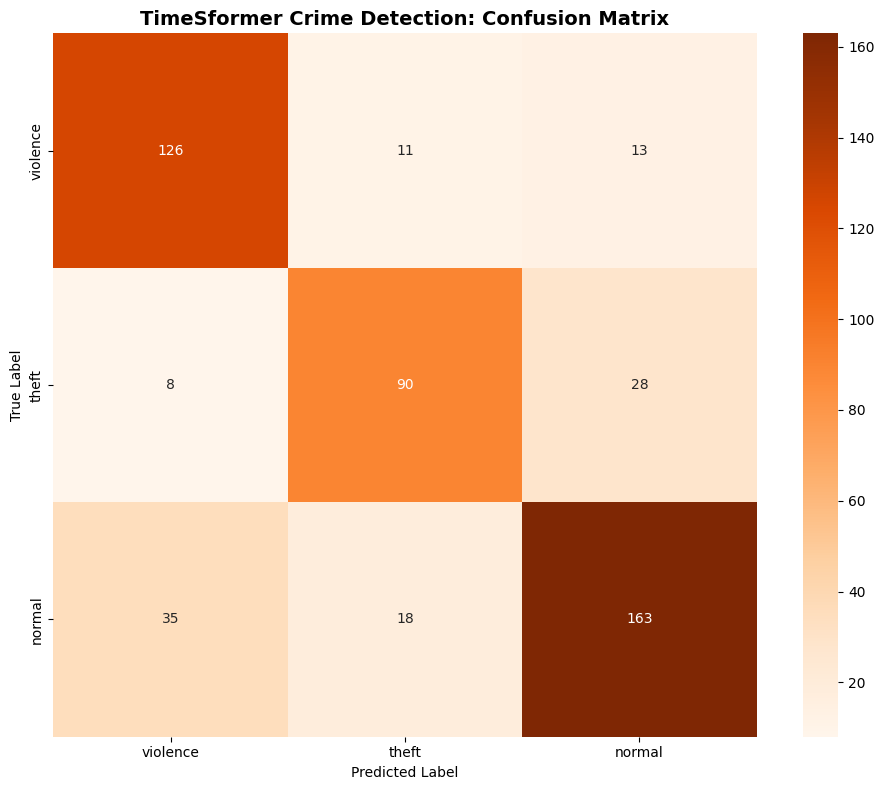

In [25]:
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=MAIN_CLASSES, yticklabels=MAIN_CLASSES, square=True)
plt.title('TimeSformer Crime Detection: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('/kaggle/working/timesformer_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


## 15. Training History Visualization\n

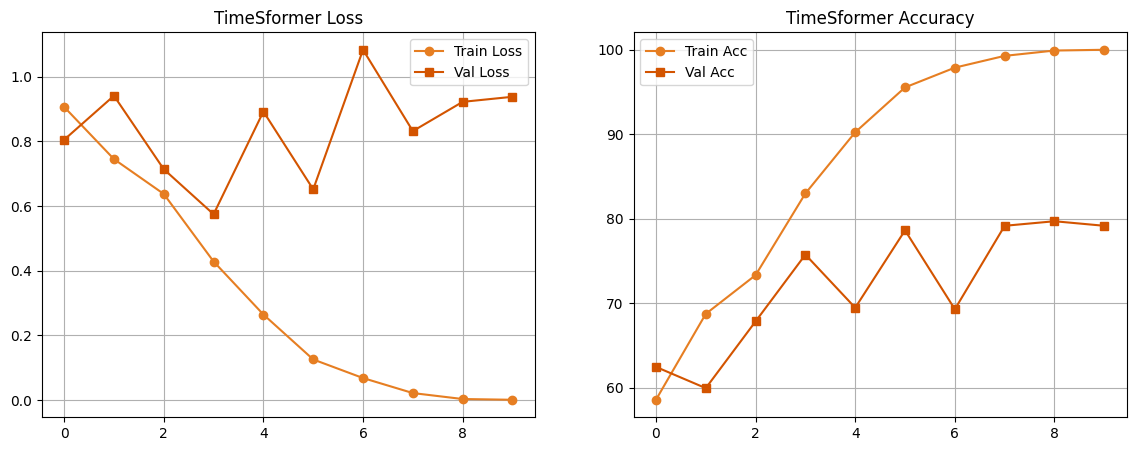

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tr_losses, 'o-', label='Train Loss', color='#e67e22')
axes[0].plot(vl_losses, 's-', label='Val Loss',   color='#d35400')
axes[0].set_title('TimeSformer Loss'); axes[0].grid(True); axes[0].legend()

axes[1].plot(tr_accs, 'o-', label='Train Acc', color='#e67e22')
axes[1].plot(vl_accs, 's-', label='Val Acc',   color='#d35400')
axes[1].set_title('TimeSformer Accuracy'); axes[1].grid(True); axes[1].legend()
plt.show()


## 16. Benchmark Summary\n

In [27]:
f1   = f1_score(test_labels, test_preds, average='macro')
prec = precision_score(test_labels, test_preds, average='macro')
rec  = recall_score(test_labels, test_preds, average='macro')

print("\n" + "="*60 + "\nSWIN3D BENCHMARK RESULTS\n" + "="*60)
print(f"  Model            : TimeSformer-T")
print(f"  Frames per clip  : {NUM_FRAMES}")
print(f"  Image size       : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Epochs           : {EPOCHS}")
print(f"  Best Val Acc     : {best_val_acc:.2f}%")
print(f"  Test Accuracy    : {test_acc:.2f}%")
print(f"  Macro F1-Score   : {f1:.4f}")
print(f"  Macro Precision  : {prec:.4f}")
print(f"  Macro Recall     : {rec:.4f}")
print("="*60)



SWIN3D BENCHMARK RESULTS
  Model            : TimeSformer-T
  Frames per clip  : 8
  Image size       : 224x224
  Epochs           : 10
  Best Val Acc     : 79.71%
  Test Accuracy    : 77.03%
  Macro F1-Score   : 0.7670
  Macro Precision  : 0.7670
  Macro Recall     : 0.7696
